# TP N°1 : Apprentissage supervisé avec Scikit-learn

**Module :** Technologies IA | **École :** ENSA Fès | **Filière :** Ingénierie Logicielle et Intelligence Artificielle (ILIA2)
**Encadrant :** Pr. Youness IDRISSI KHAMLICHI
**Réalisé par :** Manar EL BIYAALI | **N° : 12**

---

## Objectifs
- Comprendre et appliquer les étapes d'un apprentissage supervisé.
- Manipuler des modèles de **régression** et de **classification** avec Scikit-learn.
- Savoir **préparer, entraîner, évaluer et interpréter** un modèle.

## Sommaire
0. Configuration
1. **Partie 1 – Exercice 1** : Régression, tarif d'un trajet Uber
2. **Partie 1 – Exercice 2** : Classification, survie sur le Titanic
3. **Partie 2** : Mini-projet, diagnostic du cancer du sein (Breast Cancer Wisconsin, UCI)

## 0. Configuration

In [1]:
# Je commence par importer toutes les bibliothèques dont j'aurai besoin.
# pandas/numpy pour les données, matplotlib/seaborn pour les graphiques.
# Je désactive les warnings juste pour garder un notebook lisible.
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", 30)

# Fichiers attendus dans le même dossier que le notebook
#  - uber.csv  : https://www.kaggle.com/datasets/yasserh/uber-fares-dataset
#  - train.csv : https://www.kaggle.com/competitions/titanic  (renommé titanic.csv dans l'énoncé)
for f in ["uber.csv", "train.csv"]:
    print(f, "->", "OK" if os.path.exists(f) else "MANQUANT")

uber.csv -> OK
train.csv -> OK


# PARTIE 1 : Exercices

## Exercice 1 : Régression, prédiction du tarif d'un trajet Uber

**Jeu de données :** Uber Fares Dataset (Kaggle), 200 000 trajets à New York.
**Objectif :** prédire le prix d'un trajet (`fare_amount`) à partir de la distance, de l'heure, du jour de la semaine, etc.

### Étape 1 : Chargement et exploration

In [2]:
# Je charge le fichier uber.csv avec pandas et je regarde sa taille
# (lignes, colonnes) pour savoir avec quoi je travaille.
data = pd.read_csv("uber.csv")
print("Dimensions :", data.shape)
data.head()

Dimensions : (200000, 9)


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [3]:
# info() me donne le type de chaque colonne et le nombre de valeurs non nulles.
# isnull().sum() compte les valeurs manquantes par colonne.
data.info()
print("\nValeurs manquantes par colonne :")
print(data.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 13.7 MB

Valeurs manquantes par colonne :
Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


In [4]:
# describe() = statistiques de base (min, max, moyenne...).
# C'est ici que je repère les valeurs bizarres : tarifs négatifs, coordonnées impossibles...
data.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,200000.0,27712503.68,16013822.21,1.00,13825346.25,27745495.00,41555300.75,55423567.00
fare_amount,200000.0,11.36,9.90,-52.00,6.00,8.50,12.50,499.00
pickup_longitude,200000.0,-72.53,11.44,-1340.65,-73.99,-73.98,-73.97,57.42
pickup_latitude,200000.0,39.94,7.72,-74.02,40.73,40.75,40.77,1644.42
dropoff_longitude,199999.0,-72.53,13.12,-3356.67,-73.99,-73.98,-73.96,1153.57
dropoff_latitude,199999.0,39.92,6.79,-881.99,40.73,40.75,40.77,872.70
passenger_count,200000.0,1.68,1.39,0.00,1.00,1.00,2.00,208.00


**Observations**
- Le jeu contient 200 000 lignes. La cible est `fare_amount`.
- Seules `dropoff_longitude` et `dropoff_latitude` ont une valeur manquante (1 ligne).
- **Il n'y a pas de colonne `distance`** alors que l'énoncé l'utilise : il faut la calculer à partir des coordonnées GPS (formule de Haversine).
- Le `describe()` montre des **valeurs aberrantes** : tarifs négatifs, coordonnées impossibles (longitude de -3356, latitude de -881), nombre de passagers égal à 0 ou très grand.

### Étape 2 : Nettoyage et préparation

In [5]:
# Je garde le nombre de lignes de départ pour savoir combien j'en supprime à la fin.
# Attention : l'ordre est important, je nettoie d'abord, puis je crée les variables.
n0 = len(data)

data = data.dropna()                                           # 1) valeurs manquantes
data = data[data["fare_amount"] > 0]                           # 2) tarifs invalides
data = data[data["passenger_count"].between(1, 6)]             #    passagers réalistes
data = data[data["pickup_longitude"].between(-75, -72) & data["dropoff_longitude"].between(-75, -72) &
            data["pickup_latitude"].between(40, 42) & data["dropoff_latitude"].between(40, 42)]  # zone de New York

# 3) variables dérivées
data["pickup_datetime"] = pd.to_datetime(data["pickup_datetime"])
data["hour"] = data["pickup_datetime"].dt.hour
data["day_of_week"] = data["pickup_datetime"].dt.dayofweek
data["year"] = data["pickup_datetime"].dt.year

def haversine(lat1, lon1, lat2, lon2):
    """Distance à vol d'oiseau en km entre deux points GPS."""
    R = 6371
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

data["distance"] = haversine(data["pickup_latitude"], data["pickup_longitude"],
                             data["dropoff_latitude"], data["dropoff_longitude"])

# trajets de distance quasi nulle / irréaliste et tarifs extrêmes
data = data[(data["distance"] > 0.1) & (data["distance"] < 100) & (data["fare_amount"] < 150)]

print(f"Lignes avant : {n0}  |  après : {len(data)}  ({n0 - len(data)} supprimées, {100*(n0-len(data))/n0:.1f} %)")
data[["fare_amount", "distance", "hour", "day_of_week", "year", "passenger_count"]].describe().T.round(2)

Lignes avant : 200000  |  après : 191882  (8118 supprimées, 4.1 %)


,count,mean,std,min,25%,50%,75%,max
fare_amount,191882.0,11.31,9.40,0.01,6.00,8.50,12.50,148.33
distance,191882.0,3.38,3.72,0.10,1.29,2.19,3.96,99.16
hour,191882.0,13.49,6.51,0.00,9.00,14.00,19.00,23.00
day_of_week,191882.0,3.05,1.95,0.00,1.00,3.00,5.00,6.00
year,191882.0,2011.75,1.86,2009.00,2010.00,2012.00,2013.00,2015.00
passenger_count,191882.0,1.69,1.31,1.00,1.00,1.00,2.00,6.00


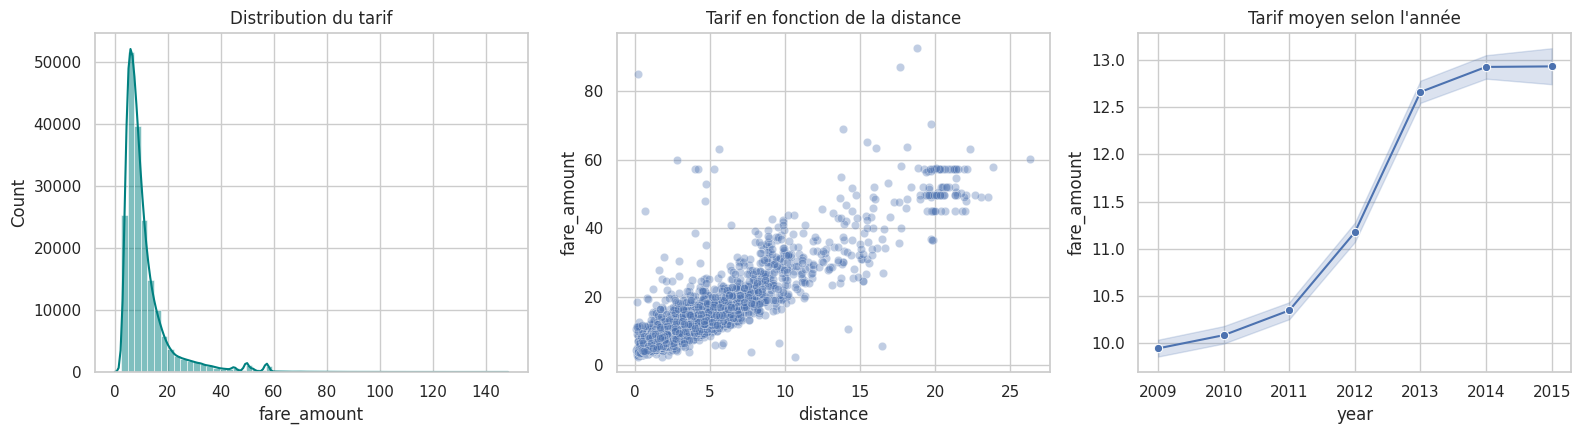

In [6]:
# Je vérifie visuellement le résultat du nettoyage :
# 1) distribution du tarif, 2) lien distance/tarif, 3) évolution du tarif selon l'année.
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(data["fare_amount"], bins=60, kde=True, ax=ax[0], color="teal")
ax[0].set_title("Distribution du tarif")
sns.scatterplot(x="distance", y="fare_amount", data=data.sample(5000, random_state=42), alpha=.35, ax=ax[1])
ax[1].set_title("Tarif en fonction de la distance")
sns.lineplot(x="year", y="fare_amount", data=data, ax=ax[2], marker="o")
ax[2].set_title("Tarif moyen selon l'année")
plt.tight_layout(); plt.show()

### Étape 3 : Séparation des données

In [7]:
# X = les variables explicatives, y = ce qu'on veut prédire (le tarif).
# On garde 20 % des données pour le test, que le modèle ne verra jamais pendant l'entraînement.
# random_state=42 pour obtenir toujours le même découpage (résultats reproductibles).
from sklearn.model_selection import train_test_split

X = data[["distance", "hour", "day_of_week"]]
y = data["fare_amount"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train :", X_train.shape, "| Test :", X_test.shape)

Train : (153505, 3) | Test : (38377, 3)


### Étape 4 : Entraînement (régression linéaire)

In [8]:
# Premier modèle : la régression linéaire. fit() = le modèle apprend sur le train.
# predict() = on lui demande de prédire les tarifs du test.
# Les coefficients montrent combien de $ chaque variable ajoute au prix.
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

print("Coefficients :", dict(zip(X.columns, lr.coef_.round(3))))
print("Intercept    :", round(lr.intercept_, 3))

Coefficients : {'distance': np.float64(2.2), 'hour': np.float64(0.01), 'day_of_week': np.float64(-0.042)}
Intercept    : 3.874


### Étape 5 : Évaluation

In [9]:
# Trois métriques pour évaluer :
# MAE  = erreur moyenne en $ ; RMSE = pareil mais punit plus les grosses erreurs ;
# R²   = part de la variance expliquée par le modèle (1 = parfait).
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print(f"MAE  = {mae:.3f} $")
print(f"RMSE = {rmse:.3f} $")
print(f"R²   = {r2:.3f}")

MAE  = 2.323 $
RMSE = 4.678 $
R²   = 0.756



**Interprétation :**
- Le coefficient de `distance` vaut ≈ **2,2 $ par km** : c'est de très loin le facteur dominant. Les coefficients de `hour` (+0,01) et `day_of_week` (-0,04) sont quasi nuls.
- R² = 0,756 : le modèle explique environ 76 % de la variance des tarifs. L'erreur typique est de ≈ 2,3 $ (MAE), mais le RMSE (4,68 $) est nettement plus grand que la MAE : quelques grosses erreurs (trajets longs ou atypiques) pèsent lourd.


### Étape 6 : Amélioration avec Random Forest

In [10]:
# Deuxième modèle : Random Forest (beaucoup d'arbres de décision dont on fait la moyenne).
# Il peut capter des relations non linéaires, contrairement à la régression linéaire.
# n_jobs=-1 : on utilise tous les coeurs du PC pour aller plus vite.
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

def scores(nom, y_true, y_hat):
    return {"Modèle": nom,
            "MAE ($)": mean_absolute_error(y_true, y_hat),
            "RMSE ($)": np.sqrt(mean_squared_error(y_true, y_hat)),
            "R²": r2_score(y_true, y_hat)}

res_uber = pd.DataFrame([scores("Régression linéaire", y_test, y_pred),
                         scores("Random Forest", y_test, y_pred_rf)]).set_index("Modèle")
res_uber.round(3)

,MAE ($),RMSE ($),R²
Modèle,,,
Régression linéaire,2.323,4.678,0.756
Random Forest,2.418,4.327,0.791


### Étape 7 : Visualisation des résultats

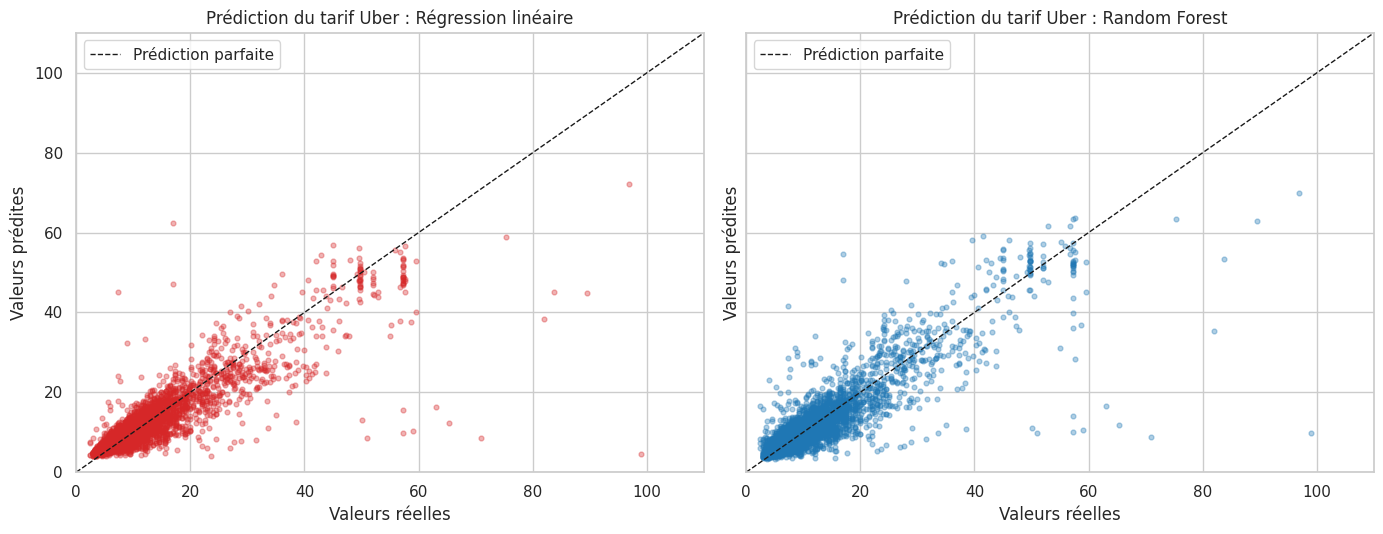

In [11]:
# Graphique réel vs prédit. Plus les points sont proches de la ligne pointillée,
# meilleur est le modèle. J'affiche seulement 5000 points pour que ce soit lisible.
idx = np.random.RandomState(42).choice(len(y_test), 5000, replace=False)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for a, pred, titre, c in [(ax[0], y_pred, "Régression linéaire", "tab:red"),
                          (ax[1], y_pred_rf, "Random Forest", "tab:blue")]:
    a.scatter(y_test.values[idx], pred[idx], alpha=0.35, s=12, color=c)
    m = 110   # axes limités à 110 $ : une prédiction aberrante (> 200 $) écrasait sinon tout le graphique
    a.plot([0, m], [0, m], "k--", lw=1, label="Prédiction parfaite")
    a.set_xlim(0, m); a.set_ylim(0, m)
    a.set_xlabel("Valeurs réelles"); a.set_ylabel("Valeurs prédites")
    a.set_title(f"Prédiction du tarif Uber : {titre}"); a.legend()
plt.tight_layout(); plt.show()

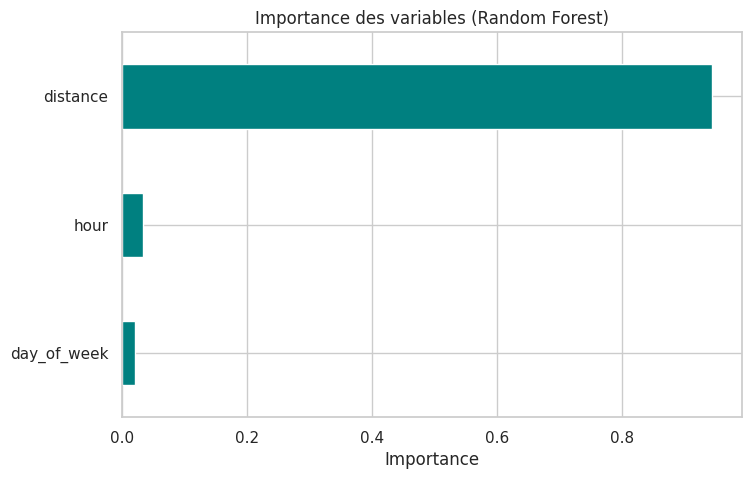

distance       0.945
hour           0.034
day_of_week    0.021
dtype: float64


In [12]:
# Quelles variables le Random Forest utilise-t-il le plus ?
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", color="teal", title="Importance des variables (Random Forest)")
plt.xlabel("Importance"); plt.show()
print(imp.sort_values(ascending=False).round(3))

### Pour aller plus loin : ajout de l'année et du nombre de passagers
Les tarifs ont évolué dans le temps (voir la courbe plus haut). On ajoute `year` et `passenger_count` aux variables.

In [13]:
# Amélioration : j'ajoute l'année et le nombre de passagers, puis je compare
# les 4 modèles dans un seul tableau.
features2 = ["distance", "hour", "day_of_week", "year", "passenger_count"]
X2_train, X2_test, y2_train, y2_test = train_test_split(data[features2], y, test_size=0.2, random_state=42)

lr2 = LinearRegression().fit(X2_train, y2_train)
rf2 = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1).fit(X2_train, y2_train)

res_uber.loc["Régression linéaire + year + passagers"] = list(scores("", y2_test, lr2.predict(X2_test)).values())[1:]
res_uber.loc["Random Forest + year + passagers"] = list(scores("", y2_test, rf2.predict(X2_test)).values())[1:]
res_uber.round(3)

,MAE ($),RMSE ($),R²
Modèle,,,
Régression linéaire,2.323,4.678,0.756
Random Forest,2.418,4.327,0.791
Régression linéaire + year + passagers,2.230,4.567,0.767
Random Forest + year + passagers,2.148,3.970,0.824


### Conclusion de l'exercice 1


| Modèle | MAE ($) | RMSE ($) | R² |
|---|---|---|---|
| Régression linéaire (distance, heure, jour) | 2,323 | 4,678 | 0,756 |
| Random Forest (distance, heure, jour) | 2,418 | 4,327 | 0,791 |
| Régression linéaire + année + passagers | 2,230 | 4,567 | 0,767 |
| **Random Forest + année + passagers** | **2,148** | **3,970** | **0,824** |

- **Le Random Forest améliore le RMSE** (4,33 $ contre 4,68 $) et le R² (0,79 contre 0,76), mais sa **MAE est un peu plus mauvaise** (2,42 $ contre 2,32 $). Le choix dépend donc de la métrique : le RMSE pénalise les grosses erreurs, la MAE reflète l'erreur typique. Hypothèse pour la MAE : avec seulement trois variables dont deux faibles (`hour`, `day_of_week`), des arbres profonds ajustent aussi du bruit sur les trajets courants.
- L'importance des variables confirme la lecture du modèle linéaire : `distance` pèse **≈ 94 %**, l'heure et le jour ≈ 3 % et 2 %.
- **Ajouter `year` et `passenger_count` aide nettement le Random Forest** (RMSE 3,97 $, R² 0,82), mais très peu la régression linéaire (R² 0,77). Cela s'explique par les données : le tarif moyen passe de ≈ 9,95 $ en 2009 à ≈ 12,9 $ en 2015, avec une hausse par paliers (2012-2013) que les arbres capturent, pas une droite.
- **Modèle retenu : Random Forest avec `year` et `passenger_count`**, meilleur sur les trois métriques.
- **Limites :** la distance de Haversine est une distance *à vol d'oiseau* (elle sous-estime le trajet réel) ; le trafic, les péages et les trajets vers les aéroports ne sont pas dans les variables ; les coordonnées brutes (zones de la ville) ne sont pas utilisées ; un seul découpage train/test est utilisé ; et la régression linéaire a prédit un tarif aberrant (> 200 $) pour un trajet dont les coordonnées sont probablement erronées (visible sur le graphique, axes limités à 110 $).


---
## Exercice 2 : Classification, prédire la survie sur le Titanic

**Jeu de données :** Titanic, Machine Learning from Disaster (Kaggle). On utilise `train.csv` (891 passagers), car c'est le seul fichier qui contient la colonne cible `Survived`.
**Objectif :** prédire si un passager a survécu (1) ou non (0).

### Étape 1 : Chargement et exploration

In [14]:
# Titanic : même démarche, je charge et je regarde les données.
# (Dans l'énoncé le fichier s'appelle titanic.csv, sur Kaggle c'est train.csv.)
data = pd.read_csv("train.csv")
print("Dimensions :", data.shape)
data.head()

Dimensions : (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [15]:
# Je regarde les valeurs manquantes : Age (177), Cabin (687), Embarked (2).
data.info()
print("\nValeurs manquantes :")
print(data.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

Valeurs manquantes :
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: in

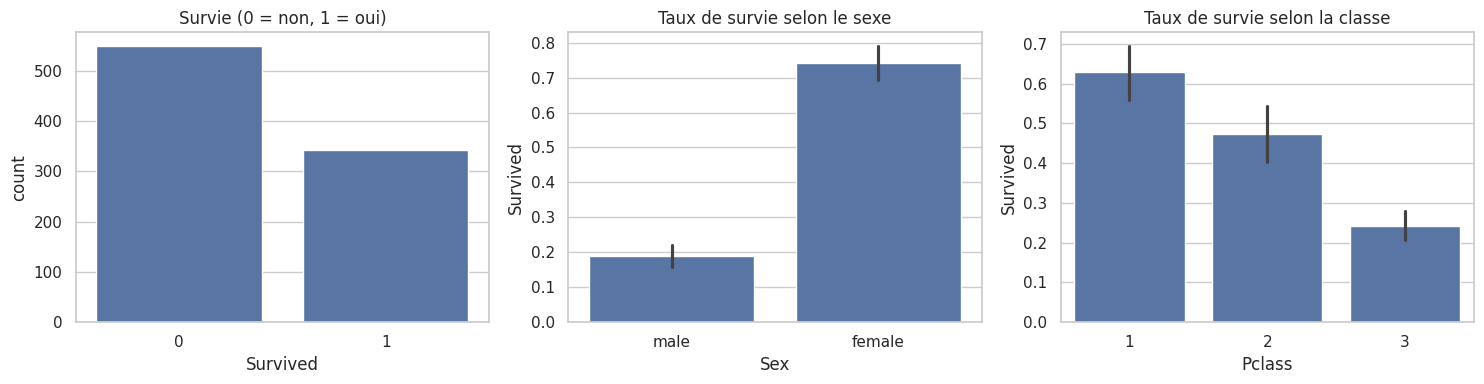

In [16]:
# Un premier coup d'oeil sur la survie : répartition globale, puis selon le sexe et la classe.
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(x="Survived", data=data, ax=ax[0]);        ax[0].set_title("Survie (0 = non, 1 = oui)")
sns.barplot(x="Sex", y="Survived", data=data, ax=ax[1]);  ax[1].set_title("Taux de survie selon le sexe")
sns.barplot(x="Pclass", y="Survived", data=data, ax=ax[2]); ax[2].set_title("Taux de survie selon la classe")
plt.tight_layout(); plt.show()

**Observations**
- `Age` (177 manquants), `Cabin` (687 manquants) et `Embarked` (2 manquants) ont des valeurs manquantes. `Cabin` est abandonnée (77 % de manquants).
- Seuls ~38 % des passagers survivent : les classes sont **déséquilibrées**, donc l'accuracy seule ne suffit pas.
- Le **sexe** et la **classe** influencent fortement la survie (les femmes et la 1ère classe survivent beaucoup plus).

### Étape 2 : Nettoyage et traitement

In [17]:
# Je garde seulement les colonnes utiles (j'enlève Name, Ticket, Cabin...).
# Age manquant -> je mets la médiane (moins sensible aux valeurs extrêmes que la moyenne).
# Embarked manquant -> je mets la valeur la plus fréquente (le mode).
data = data[["Survived", "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]].copy()
data["Age"] = data["Age"].fillna(data["Age"].median())
data["Embarked"] = data["Embarked"].fillna(data["Embarked"].mode()[0])
print("Valeurs manquantes restantes :", data.isnull().sum().sum())
data.head()

Valeurs manquantes restantes : 0


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


### Étape 3 : Encodage des variables catégorielles

In [18]:
# Les modèles ne comprennent pas le texte, donc je transforme Sex et Embarked en nombres.
# J'affiche la correspondance pour vérifier que l'encodage est bon.
from sklearn.preprocessing import LabelEncoder

le_sex, le_emb = LabelEncoder(), LabelEncoder()
data["Sex"] = le_sex.fit_transform(data["Sex"])
data["Embarked"] = le_emb.fit_transform(data["Embarked"])
print("Sex      :", {c: int(i) for i, c in enumerate(le_sex.classes_)})
print("Embarked :", {c: int(i) for i, c in enumerate(le_emb.classes_)})
data.head()

Sex      : {'female': 0, 'male': 1}
Embarked : {'C': 0, 'Q': 1, 'S': 2}


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,1,22.0,1,0,7.2500,2
1,1,1,0,38.0,1,0,71.2833,0
2,1,3,0,26.0,0,0,7.9250,2
3,1,1,0,35.0,1,0,53.1000,2
4,0,3,1,35.0,0,0,8.0500,2


### Étape 4 : Séparation des données

In [19]:
# X = toutes les colonnes sauf la cible, y = la colonne Survived.
# Même découpage 80/20 qu'avant.
X = data.drop("Survived", axis=1)
y = data["Survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train :", X_train.shape, "| Test :", X_test.shape)

Train : (712, 7) | Test : (179, 7)


### Étape 5 : Entraînement des modèles

In [20]:
# Deux modèles de classification : régression logistique et Random Forest.
# max_iter=1000 pour que la régression logistique ait le temps de converger.
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

log_model = LogisticRegression(max_iter=1000)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

log_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)
print("Modèles entraînés")

Modèles entraînés


### Étape 6 : Évaluation des modèles

In [21]:
# Accuracy = pourcentage de bonnes prédictions.
# classification_report donne en plus precision, recall et F1 pour chaque classe,
# ce qui est plus utile quand les classes ne sont pas équilibrées.
from sklearn.metrics import accuracy_score, classification_report

y_pred_log = log_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

print("Accuracy (Logistic)      :", round(accuracy_score(y_test, y_pred_log), 4))
print("Accuracy (Random Forest) :", round(accuracy_score(y_test, y_pred_rf), 4))
print("\n--- Random Forest ---")
print(classification_report(y_test, y_pred_rf, target_names=["Décédé (0)", "Survivant (1)"]))
print("--- Régression logistique ---")
print(classification_report(y_test, y_pred_log, target_names=["Décédé (0)", "Survivant (1)"]))

Accuracy (Logistic)      : 0.8101
Accuracy (Random Forest) : 0.8212

--- Random Forest ---
               precision    recall  f1-score   support

   Décédé (0)       0.83      0.88      0.85       105
Survivant (1)       0.81      0.74      0.77        74

     accuracy                           0.82       179
    macro avg       0.82      0.81      0.81       179
 weighted avg       0.82      0.82      0.82       179

--- Régression logistique ---
               precision    recall  f1-score   support

   Décédé (0)       0.83      0.86      0.84       105
Survivant (1)       0.79      0.74      0.76        74

     accuracy                           0.81       179
    macro avg       0.81      0.80      0.80       179
 weighted avg       0.81      0.81      0.81       179



### Étape 7 : Matrice de confusion

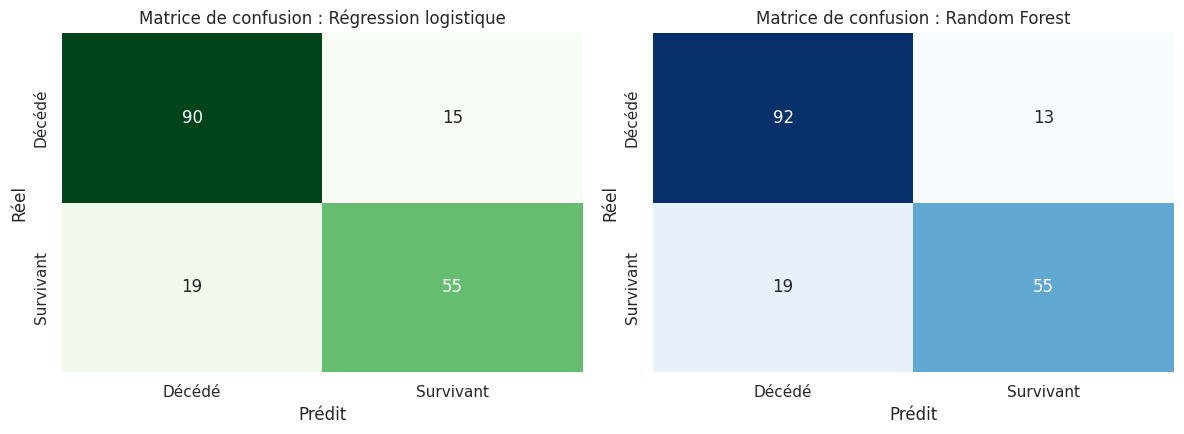

In [22]:
# Matrice de confusion : lignes = réalité, colonnes = prédiction.
# La diagonale = bonnes prédictions ; en dehors = erreurs.
from sklearn.metrics import confusion_matrix

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, pred, titre, cmap in [(ax[0], y_pred_log, "Régression logistique", "Greens"),
                             (ax[1], y_pred_rf, "Random Forest", "Blues")]:
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap=cmap, ax=a, cbar=False,
                xticklabels=["Décédé", "Survivant"], yticklabels=["Décédé", "Survivant"])
    a.set_title(f"Matrice de confusion : {titre}"); a.set_xlabel("Prédit"); a.set_ylabel("Réel")
plt.tight_layout(); plt.show()

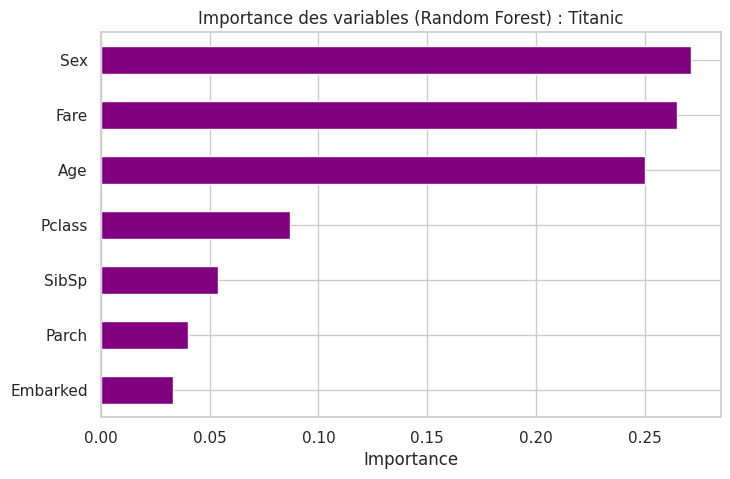

Sex         0.271
Fare        0.265
Age         0.250
Pclass      0.087
SibSp       0.054
Parch       0.040
Embarked    0.033
dtype: float64


In [23]:
# Importance des variables pour le Random Forest sur le Titanic.
imp = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", color="purple", title="Importance des variables (Random Forest) : Titanic")
plt.xlabel("Importance"); plt.show()
print(imp.sort_values(ascending=False).round(3))

### Pour aller plus loin : validation croisée
Avec seulement 179 passagers dans le test, une seule séparation donne un résultat peu fiable. On compare les deux modèles en **validation croisée stratifiée (5 plis)**. L'imputation de l'âge est faite *dans* chaque pli (pipeline), pour éviter toute fuite d'information du jeu de validation vers l'entraînement.

In [24]:
# Avec seulement 179 passagers en test, le résultat dépend beaucoup du hasard du découpage.
# Je refais donc la comparaison avec une validation croisée à 5 plis : on entraîne et on teste
# 5 fois sur des morceaux différents, puis on fait la moyenne.
# Je mets l'imputation dans un pipeline pour qu'elle soit recalculée dans chaque pli (pas de triche).
# Ici j'utilise aussi un one-hot pour Embarked, plus propre que LabelEncoder.
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

raw = pd.read_csv("train.csv")[["Survived", "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]]
raw["Sex"] = (raw["Sex"] == "male").astype(int)
raw = pd.get_dummies(raw, columns=["Embarked"], dtype=int)      # one-hot : pas d'ordre artificiel entre C, Q, S
Xr, yr = raw.drop("Survived", axis=1), raw["Survived"]

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
modeles = {
    "Régression logistique": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest":         make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(n_estimators=200, random_state=42)),
    "Random Forest (prof. limitée)": make_pipeline(SimpleImputer(strategy="median"),
                                                   RandomForestClassifier(n_estimators=200, max_depth=5, min_samples_leaf=3, random_state=42)),
}
rows = []
for nom, m in modeles.items():
    s = cross_val_score(m, Xr, yr, cv=skf, scoring="accuracy")
    rows.append({"Modèle": nom, "Accuracy moyenne": s.mean(), "Écart-type": s.std()})
pd.DataFrame(rows).set_index("Modèle").round(4)

,Accuracy moyenne,Écart-type
Modèle,,
Régression logistique,0.7924,0.0207
Random Forest,0.8148,0.0243
Random Forest (prof. limitée),0.8305,0.0123


### Conclusion de l'exercice 2


| Évaluation | Régression logistique | Random Forest |
|---|---|---|
| Accuracy sur le test (179 passagers) | 0,810 | 0,821 |
| Accuracy en validation croisée 5 plis | 0,792 ± 0,021 | 0,815 ± 0,024 |
| Random Forest à profondeur limitée (CV) | | **0,831 ± 0,012** |

- **Sur le jeu de test, l'écart (0,810 contre 0,821) représente 2 passagers sur 179** : il n'est pas significatif. La validation croisée est plus fiable, et elle montre que la régression logistique faisait mieux sur ce découpage (0,810) que sa performance moyenne (0,792).
- **Le Random Forest par défaut surapprend** (arbres de profondeur illimitée). En limitant la profondeur (`max_depth=5`, `min_samples_leaf=3`), l'accuracy monte à 0,831 et l'écart-type baisse de moitié (0,012) : c'est le modèle le plus précis **et** le plus stable.
- **Les deux modèles repèrent mieux les décédés que les survivants** (recall ≈ 0,86-0,88 contre 0,74) : la classe « survivant » est minoritaire (38 %). Une accuracy de 82 % cache donc environ 1 survivant sur 4 mal classé.
- **Importance des variables (Random Forest) :** `Sex` (0,27), `Fare` (0,27) et `Age` (0,25), puis `Pclass` (0,09). Il faut rester prudent : `Fare` et `Age` sont continues et offrent beaucoup de points de coupure aux arbres, ce qui gonfle leur importance, et 177 âges ont été remplacés par la médiane. Les graphiques de l'exploration (survie selon sexe et classe) restent la lecture la plus solide : « les femmes d'abord » et l'avantage de la 1ère classe.
- **Limites :** `LabelEncoder` sur `Embarked` crée un ordre artificiel (C < Q < S), sans conséquence pour les arbres mais discutable pour la régression logistique (corrigé par un encodage one-hot dans la partie validation croisée) ; aucune variable construite à partir du nom (titre) ni de la taille de la famille ; le test ne contient que 74 survivants.
- **Modèle retenu : Random Forest à profondeur limitée.**


---
# PARTIE 2 : Mini-projet et compte rendu
## Diagnostic du cancer du sein : Breast Cancer Wisconsin (Diagnostic), UCI

**Problème :** à partir de 30 mesures calculées sur des images de cellules (noyaux de cellules prélevées par biopsie à l'aiguille fine), prédire si une tumeur est **maligne** ou **bénigne**.
**Source :** UCI Machine Learning Repository (disponible dans Scikit-learn via `load_breast_cancer`). 569 patientes.

**Pourquoi ce jeu de données ?** Le coût des erreurs n'est pas symétrique : manquer une tumeur maligne (faux négatif) est beaucoup plus grave qu'une fausse alerte (faux positif). Le choix du modèle ne peut donc pas se réduire à l'accuracy, ce qui permet une vraie comparaison critique.

## 1. Chargement et exploration

In [25]:
# Mini-projet : dataset Breast Cancer Wisconsin (UCI), intégré à scikit-learn.
# Dans sklearn 0 = maligne et 1 = bénigne. Je l'inverse pour que 1 = maligne :
# comme ça le recall mesure directement la détection des tumeurs malignes.
from sklearn.datasets import load_breast_cancer

bc = load_breast_cancer(as_frame=True)
df = bc.frame.copy()

# Dans Scikit-learn : 0 = malin, 1 = bénin. On inverse pour que la classe POSITIVE (1) soit "maligne" :
# precision/recall/F1 se lisent alors directement comme "détection des tumeurs malignes".
df["malignant"] = 1 - df["target"]
df = df.drop(columns="target")

print("Dimensions :", df.shape)
print("Valeurs manquantes :", int(df.isnull().sum().sum()))
print("\nRépartition de la cible :")
print(df["malignant"].map({0: "bénigne", 1: "maligne"}).value_counts())
df.head()

Dimensions : (569, 31)
Valeurs manquantes : 0

Répartition de la cible :
malignant
bénigne    357
maligne    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,...,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,...,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,...,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,...,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,...,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,...,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


In [26]:
# Statistiques descriptives (j'affiche seulement les 12 premières variables).
df.describe().T.round(2).head(12)

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.13,3.52,6.98,11.70,13.37,15.78,28.11
mean texture,569.0,19.29,4.30,9.71,16.17,18.84,21.80,39.28
mean perimeter,569.0,91.97,24.30,43.79,75.17,86.24,104.10,188.50
mean area,569.0,654.89,351.91,143.50,420.30,551.10,782.70,2501.00
mean smoothness,569.0,0.10,0.01,0.05,0.09,0.10,0.11,0.16
mean compactness,569.0,0.10,0.05,0.02,0.06,0.09,0.13,0.35
mean concavity,569.0,0.09,0.08,0.00,0.03,0.06,0.13,0.43
mean concave points,569.0,0.05,0.04,0.00,0.02,0.03,0.07,0.20
mean symmetry,569.0,0.18,0.03,0.11,0.16,0.18,0.20,0.30
mean fractal dimension,569.0,0.06,0.01,0.05,0.06,0.06,0.07,0.10


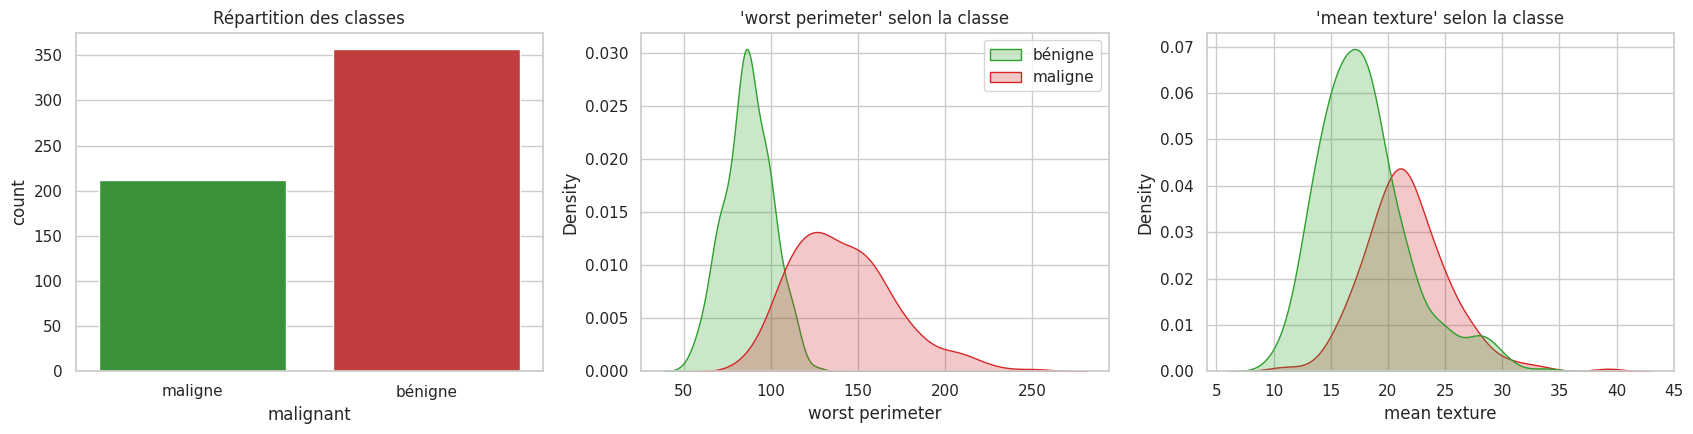

In [27]:
# Graphiques : répartition des classes, puis comment deux variables se comportent selon la classe.
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.countplot(x=df["malignant"].map({0: "bénigne", 1: "maligne"}), ax=ax[0], palette=["tab:green", "tab:red"])
ax[0].set_title("Répartition des classes")
for c, col in zip(["tab:green", "tab:red"], [0, 1]):
    sns.kdeplot(df.loc[df["malignant"] == col, "worst perimeter"], ax=ax[1], color=c, fill=True,
                label="bénigne" if col == 0 else "maligne")
ax[1].set_title("'worst perimeter' selon la classe"); ax[1].legend()
sns.kdeplot(data=df, x="mean texture", hue="malignant", ax=ax[2], fill=True, palette=["tab:green", "tab:red"], legend=False)
ax[2].set_title("'mean texture' selon la classe")
plt.tight_layout(); plt.show()

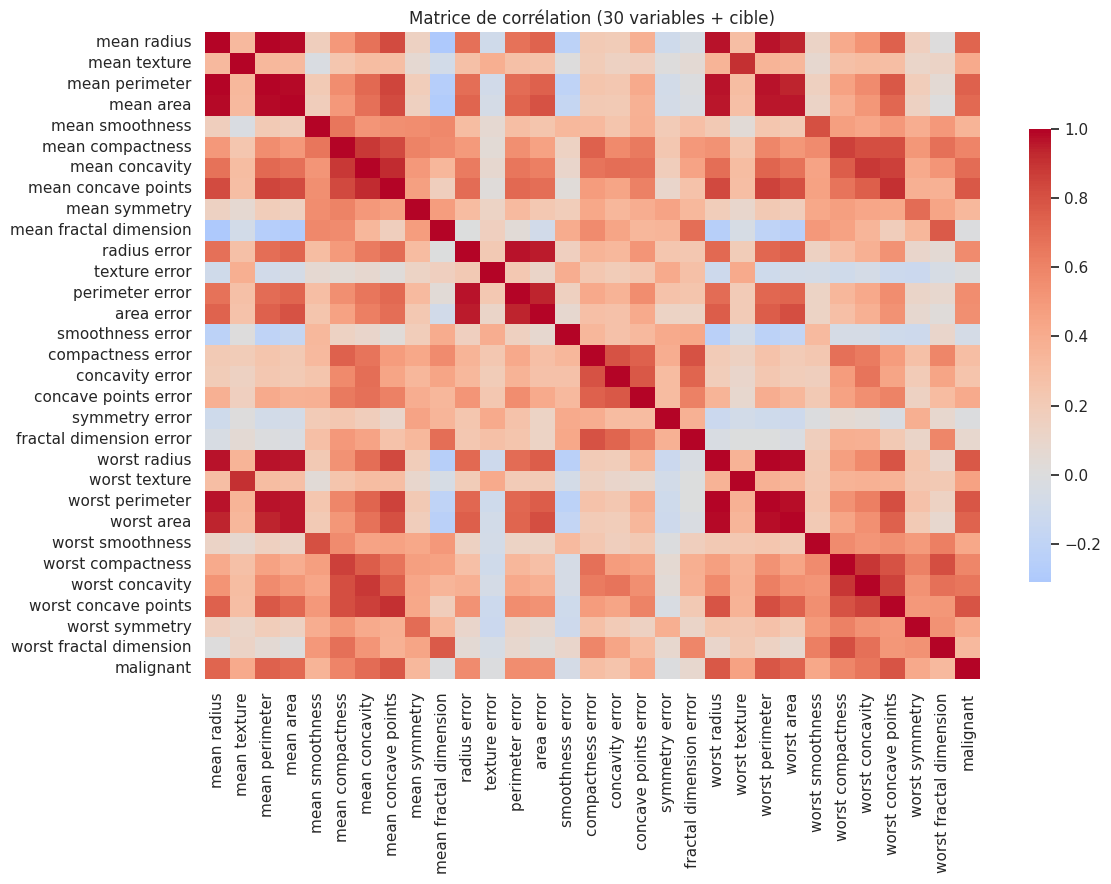

Corrélation avec la cible (top 6) :
worst concave points    0.794
worst perimeter         0.783
mean concave points     0.777
worst radius            0.776
mean perimeter          0.743
worst area              0.734
Name: malignant, dtype: float64

Nombre de paires de variables corrélées à plus de 0.95 : 15


In [28]:
# Matrice de corrélation : je veux savoir (1) quelles variables sont liées à la cible
# et (2) quelles variables sont redondantes entre elles.
corr = df.corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, xticklabels=True, yticklabels=True, cbar_kws={"shrink": .7})
plt.title("Matrice de corrélation (30 variables + cible)"); plt.tight_layout(); plt.show()

print("Corrélation avec la cible (top 6) :")
print(corr["malignant"].drop("malignant").abs().sort_values(ascending=False).head(6).round(3))

# paires de variables très corrélées entre elles
pairs = (corr.drop(index="malignant", columns="malignant").abs().where(np.triu(np.ones((30, 30)), 1).astype(bool))
         .stack().loc[lambda s: s > 0.95].sort_values(ascending=False))
print(f"\nNombre de paires de variables corrélées à plus de 0.95 : {len(pairs)}")


**Observations**
- 569 patientes, 30 variables numériques, **aucune valeur manquante**. Les classes sont modérément déséquilibrées : 357 tumeurs bénignes (63 %) et 212 malignes (37 %). Une accuracy de 63 % s'obtiendrait en prédisant toujours « bénigne » : c'est la référence à battre, et l'accuracy seule serait trompeuse.
- Les variables les plus liées à la cible sont `worst concave points` (0,79), `worst perimeter` (0,78), `mean concave points` (0,78) et `worst radius` (0,78) : les tumeurs malignes ont des noyaux plus grands et au contour plus irrégulier. Les densités montrent une séparation nette des classes sur `worst perimeter`, beaucoup moins sur `mean texture`.
- **15 paires de variables ont une corrélation supérieure à 0,95** (rayon, périmètre et aire sont liés géométriquement). Il y a donc beaucoup de redondance : cela gêne l'interprétation des coefficients, pas la prédiction.
- Le problème semble « facile » (classes bien séparées) : on s'attend à ce que tous les bons modèles dépassent 95 %. Les différences seront petites, d'où l'importance d'une comparaison rigoureuse (validation croisée répétée, écarts-types) plutôt que d'un seul score sur le test.


## 2. Prétraitement

Choix de prétraitement et justifications :
1. **Séparation stratifiée 80/20 faite en premier** : le jeu de test reste intact jusqu'à l'évaluation finale et garde la même proportion de tumeurs malignes (`stratify=y`).
2. **Standardisation** (`StandardScaler`) : indispensable pour la régression logistique, KNN et SVM, qui sont sensibles à l'échelle des variables (l'aire vaut des centaines, la finesse des centièmes). Inutile pour les arbres, mais sans effet négatif.
3. **Aucune imputation ni encodage** : pas de valeurs manquantes, toutes les variables sont numériques.
4. **Tout dans un `Pipeline`** : le scaler est réappris sur chaque pli de validation croisée, ce qui évite toute fuite de données.
5. **Variables corrélées conservées** : les arbres et le SVM les gèrent bien, et la régression logistique sera régularisée (L2).

In [29]:
# stratify=y garde la même proportion de tumeurs malignes dans le train et dans le test.
# Je sépare AVANT tout le reste pour que le test reste vraiment neuf.
from sklearn.model_selection import train_test_split

X = df.drop(columns="malignant")
y = df["malignant"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("Train :", X_train.shape, "| Test :", X_test.shape)
print("Part de malignes  train : %.1f %%  |  test : %.1f %%" % (100*y_train.mean(), 100*y_test.mean()))

Train : (455, 30) | Test : (114, 30)
Part de malignes  train : 37.4 %  |  test : 36.8 %


## 3. Comparaison rigoureuse des modèles
On compare **6 modèles** de familles différentes (linéaire, voisinage, noyau, arbre, bagging, boosting) avec le même découpage : **validation croisée stratifiée 5 plis répétée 3 fois (15 évaluations)**, uniquement sur le jeu d'entraînement. Le jeu de test n'est utilisé qu'une fois, à la fin.
Métriques : **recall** (part des tumeurs malignes détectées), **precision**, **F1**, **ROC-AUC** et accuracy.

In [30]:
# Je prépare 6 modèles de familles différentes. Chacun est dans un Pipeline avec un StandardScaler :
# le scaler est réappris à chaque pli de validation croisée, donc aucune fuite de données.
# Validation croisée 5 plis répétée 3 fois = 15 évaluations par modèle, plus fiable qu'un seul score.
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

def pipe(model): return Pipeline([("scaler", StandardScaler()), ("model", model)])

modeles = {
    "Régression logistique": pipe(LogisticRegression(max_iter=5000)),
    "KNN (k=5)":             pipe(KNeighborsClassifier(n_neighbors=5)),
    "SVM (RBF)":             pipe(SVC(probability=True, random_state=42)),
    "Arbre de décision":     pipe(DecisionTreeClassifier(max_depth=4, random_state=42)),
    "Random Forest":         pipe(RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)),
    "Gradient Boosting":     pipe(GradientBoostingClassifier(random_state=42)),
}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

lignes = []
for nom, m in modeles.items():
    r = cross_validate(m, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    lignes.append({"Modèle": nom, **{k: r[f"test_{k}"].mean() for k in scoring},
                   "recall (écart-type)": r["test_recall"].std(), "roc_auc (écart-type)": r["test_roc_auc"].std()})
res_cv = pd.DataFrame(lignes).set_index("Modèle").sort_values("roc_auc", ascending=False)
res_cv.round(4)

,accuracy,precision,recall,f1,roc_auc,recall (écart-type),roc_auc (écart-type)
Modèle,,,,,,,
Régression logistique,0.9758,0.9788,0.9569,0.9672,0.9960,0.0301,0.0046
SVM (RBF),0.9714,0.9784,0.9451,0.9606,0.9949,0.0466,0.0052
Gradient Boosting,0.9560,0.9526,0.9294,0.9398,0.9899,0.0556,0.0089
Random Forest,0.9553,0.9550,0.9255,0.9389,0.9898,0.0514,0.0076
KNN (k=5),0.9641,0.9873,0.9157,0.9494,0.9839,0.0546,0.0180
Arbre de décision,0.9223,0.9233,0.8667,0.8918,0.9023,0.0781,0.0519


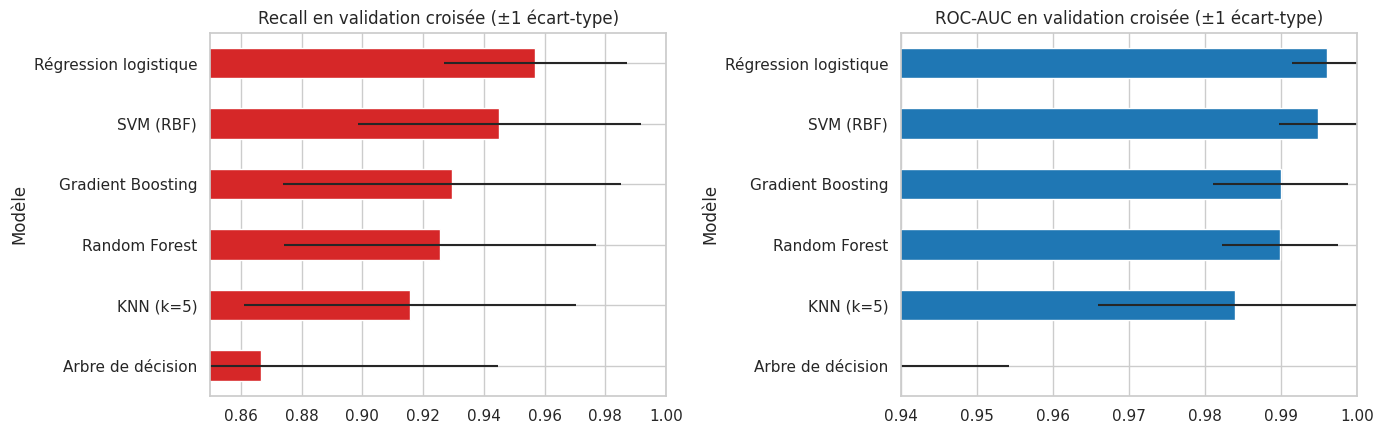

In [31]:
# Barres d'erreur = écart-type : si deux modèles se chevauchent, leur différence n'est pas significative.
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
res_cv["recall"].sort_values().plot(kind="barh", ax=ax[0], color="tab:red", xerr=res_cv["recall (écart-type)"].reindex(res_cv["recall"].sort_values().index))
ax[0].set_xlim(0.85, 1.0); ax[0].set_title("Recall en validation croisée (±1 écart-type)")
res_cv["roc_auc"].sort_values().plot(kind="barh", ax=ax[1], color="tab:blue", xerr=res_cv["roc_auc (écart-type)"].reindex(res_cv["roc_auc"].sort_values().index))
ax[1].set_xlim(0.94, 1.0); ax[1].set_title("ROC-AUC en validation croisée (±1 écart-type)")
plt.tight_layout(); plt.show()


**Lecture des résultats (validation croisée 5 plis × 3 répétitions) :**
- La **régression logistique est première sur toutes les métriques** : ROC-AUC 0,996, recall 0,957, F1 0,967, accuracy 0,976, avec en plus l'écart-type de recall le plus faible (0,030) : elle est aussi la plus stable.
- Le **SVM RBF** est très proche (AUC 0,995, recall 0,945). La différence d'AUC entre les deux (0,001) est **plus petite que l'écart-type** (≈ 0,005) : on ne peut pas les départager statistiquement.
- Random Forest et Gradient Boosting sont un cran en dessous (AUC ≈ 0,990, recall ≈ 0,93). **KNN** a la meilleure precision (0,987) mais détecte moins de tumeurs malignes (recall 0,916).
- L'**arbre de décision** est nettement le moins bon et le plus instable (recall 0,867, AUC 0,902, écart-type d'AUC 0,052).
- Constat important : **un modèle linéaire simple fait aussi bien que les modèles complexes**. Après standardisation, les classes sont presque linéairement séparables, et avec 455 exemples pour 30 variables, la flexibilité supplémentaire des ensembles n'apporte rien.


## 4. Optimisation des hyperparamètres
Les deux meilleurs modèles (régression logistique et SVM) sont optimisés par `GridSearchCV` (5 plis) sur le **ROC-AUC**, métrique qui ne dépend pas d'un seuil de décision.

In [32]:
# GridSearchCV essaie toutes les combinaisons d'hyperparamètres avec validation croisée
# et garde la meilleure. Je l'applique aux deux meilleurs modèles seulement.
from sklearn.model_selection import GridSearchCV, StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

gs_lr = GridSearchCV(pipe(LogisticRegression(max_iter=5000)),
                     {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30]},
                     cv=skf, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)

gs_svm = GridSearchCV(pipe(SVC(probability=True, random_state=42)),
                      {"model__C": [0.3, 1, 3, 10, 30], "model__gamma": ["scale", 0.003, 0.01, 0.03], "model__kernel": ["rbf", "linear"]},
                      cv=skf, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)

print("Régression logistique :", gs_lr.best_params_, "| ROC-AUC CV =", round(gs_lr.best_score_, 4))
print("SVM                   :", gs_svm.best_params_, "| ROC-AUC CV =", round(gs_svm.best_score_, 4))

Régression logistique : {'model__C': 1} | ROC-AUC CV = 0.9958
SVM                   : {'model__C': 30, 'model__gamma': 0.003, 'model__kernel': 'rbf'} | ROC-AUC CV = 0.9961


## 5. Évaluation finale sur le jeu de test

In [33]:
# Maintenant seulement, j'utilise le jeu de test (une seule fois).
# J'ajoute le nombre de faux négatifs (tumeur maligne ratée) car c'est l'erreur la plus grave ici.
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

finaux = {nom: m.fit(X_train, y_train) for nom, m in modeles.items()}
finaux["Régression logistique (optimisée)"] = gs_lr.best_estimator_
finaux["SVM (optimisé)"] = gs_svm.best_estimator_

lignes = []
for nom, m in finaux.items():
    p = m.predict(X_test); proba = m.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    lignes.append({"Modèle": nom, "Accuracy": accuracy_score(y_test, p), "Precision": precision_score(y_test, p),
                   "Recall": recall_score(y_test, p), "F1": f1_score(y_test, p), "ROC-AUC": roc_auc_score(y_test, proba),
                   "Faux négatifs": fn, "Faux positifs": fp})
res_test = pd.DataFrame(lignes).set_index("Modèle").sort_values(["Faux négatifs", "Faux positifs"])
res_test.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC,Faux négatifs,Faux positifs
Modèle,,,,,,,
SVM (optimisé),0.9825,1.0000,0.9524,0.9756,0.9960,2,0
SVM (RBF),0.9737,1.0000,0.9286,0.9630,0.9947,3,0
Random Forest,0.9737,1.0000,0.9286,0.9630,0.9944,3,0
Régression logistique,0.9649,0.9750,0.9286,0.9512,0.9960,3,1
Régression logistique (optimisée),0.9649,0.9750,0.9286,0.9512,0.9960,3,1
Gradient Boosting,0.9649,1.0000,0.9048,0.9500,0.9947,4,0
KNN (k=5),0.9561,0.9744,0.9048,0.9383,0.9823,4,1
Arbre de décision,0.9123,0.9444,0.8095,0.8718,0.8770,8,2


## 6. Interprétation des résultats

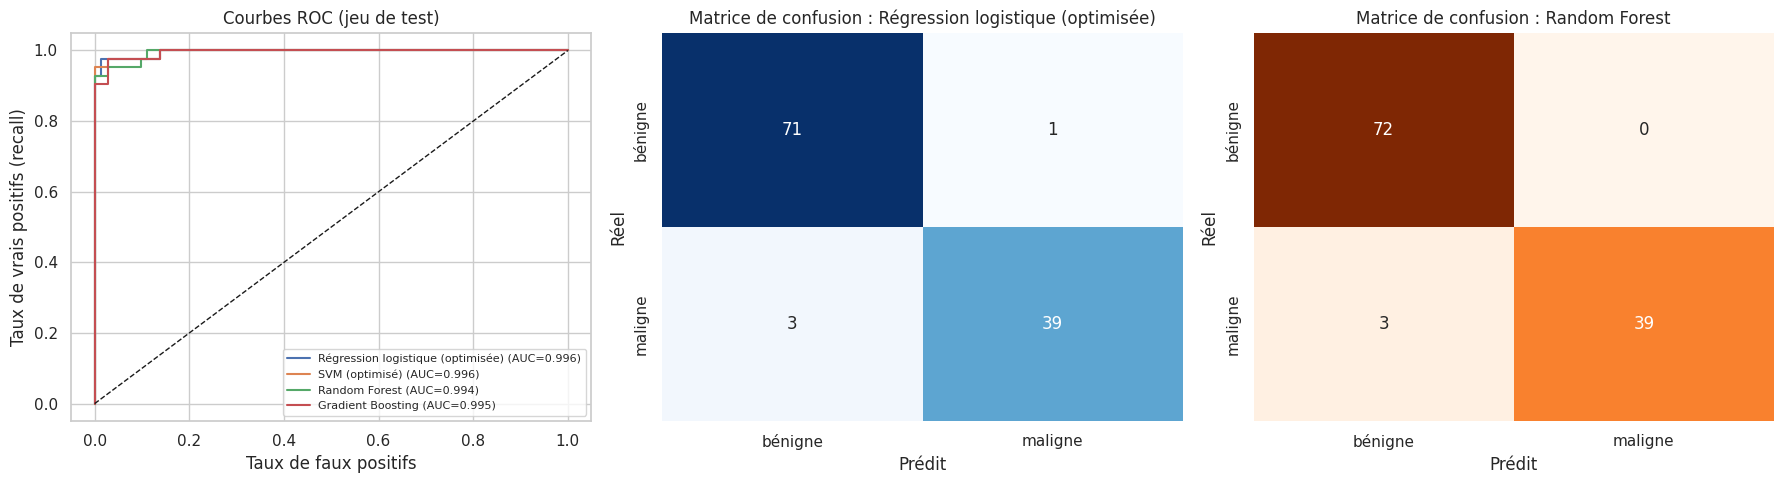

In [34]:
# Courbes ROC + matrices de confusion de deux modèles.
from sklearn.metrics import roc_curve

choix = ["Régression logistique (optimisée)", "SVM (optimisé)", "Random Forest", "Gradient Boosting"]
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# (a) courbes ROC
for nom in choix:
    fpr, tpr, _ = roc_curve(y_test, finaux[nom].predict_proba(X_test)[:, 1])
    ax[0].plot(fpr, tpr, label=f"{nom} (AUC={res_test.loc[nom, 'ROC-AUC']:.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_xlabel("Taux de faux positifs"); ax[0].set_ylabel("Taux de vrais positifs (recall)")
ax[0].set_title("Courbes ROC (jeu de test)"); ax[0].legend(loc="lower right", fontsize=8)

# (b)(c) matrices de confusion de deux modèles
for a, nom, cmap in [(ax[1], "Régression logistique (optimisée)", "Blues"), (ax[2], "Random Forest", "Oranges")]:
    cm = confusion_matrix(y_test, finaux[nom].predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap=cmap, cbar=False, ax=a,
                xticklabels=["bénigne", "maligne"], yticklabels=["bénigne", "maligne"])
    a.set_title(f"Matrice de confusion : {nom}"); a.set_xlabel("Prédit"); a.set_ylabel("Réel")
plt.tight_layout(); plt.show()

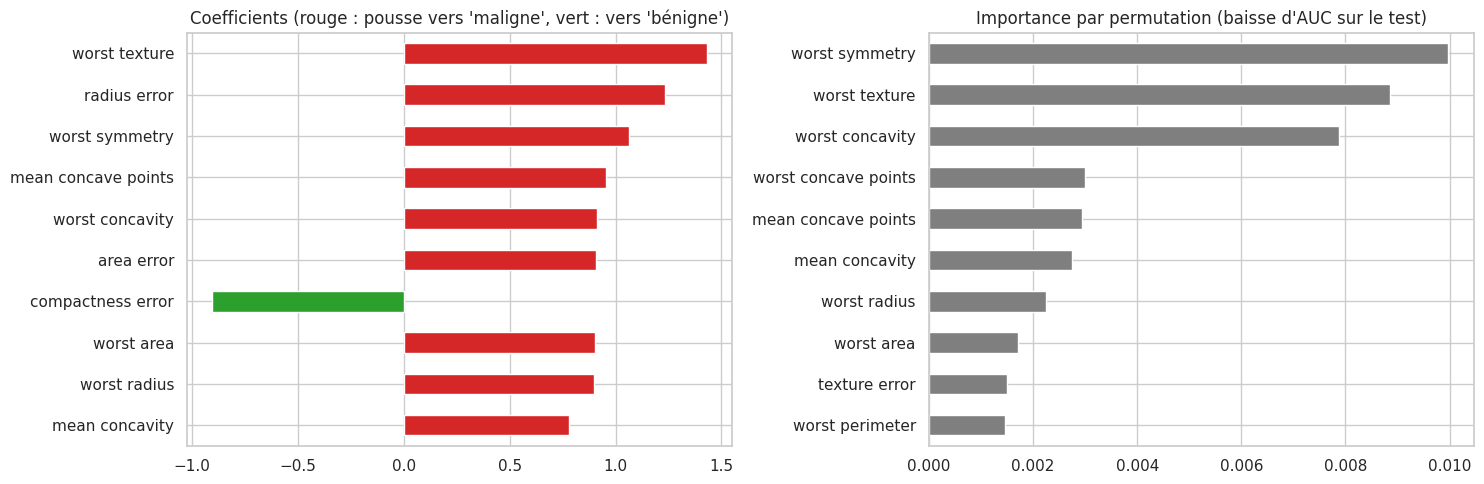

Top coefficients :
 worst texture          1.43
radius error           1.23
worst symmetry         1.06
mean concave points    0.95
worst concavity        0.91
area error             0.91
worst area             0.90
worst radius           0.90
mean concavity         0.78
compactness error     -0.91
dtype: float64


In [35]:
# Deux lectures de l'importance des variables pour le modèle retenu (régression logistique) :
#  (a) coefficients sur variables standardisées : sens et force de l'effet (global, sur le modèle appris)
#  (b) importance par permutation sur le test : baisse d'AUC quand une variable est mélangée
from sklearn.inspection import permutation_importance

modele_retenu = finaux["Régression logistique (optimisée)"]
coef = pd.Series(modele_retenu.named_steps["model"].coef_[0], index=X.columns)
top_coef = coef.reindex(coef.abs().sort_values().tail(10).index)

pi = permutation_importance(modele_retenu, X_test, y_test, n_repeats=20, random_state=42, scoring="roc_auc", n_jobs=-1)
top_pi = pd.Series(pi.importances_mean, index=X.columns).sort_values().tail(10)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
top_coef.plot(kind="barh", ax=ax[0], color=["tab:red" if v > 0 else "tab:green" for v in top_coef])
ax[0].set_title("Coefficients (rouge : pousse vers 'maligne', vert : vers 'bénigne')")
top_pi.plot(kind="barh", ax=ax[1], color="tab:gray")
ax[1].set_title("Importance par permutation (baisse d'AUC sur le test)")
plt.tight_layout(); plt.show()
print("Top coefficients :\n", top_coef.sort_values(ascending=False).round(2))

In [36]:
# Seuil de décision. Par défaut 0.5, mais ici un faux négatif (tumeur maligne manquée) coûte bien plus cher
# qu'une fausse alerte (qui sera vérifiée par un examen complémentaire).
# Pour éviter de choisir le seuil sur le jeu de test, on le choisit avec des prédictions "out-of-fold" sur le TRAIN.
from sklearn.model_selection import cross_val_predict

proba_oof = cross_val_predict(modele_retenu, X_train, y_train, cv=skf, method="predict_proba")[:, 1]
lignes = []
for seuil in [0.5, 0.4, 0.3, 0.2, 0.1]:
    p = (proba_oof >= seuil).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, p).ravel()
    lignes.append({"Seuil": seuil, "Faux négatifs": fn, "Faux positifs": fp,
                   "Recall": recall_score(y_train, p), "Precision": precision_score(y_train, p)})
tab_seuil = pd.DataFrame(lignes).set_index("Seuil")
display(tab_seuil.round(3))

# Règle fixée à l'avance : le seuil le plus bas qui garde une precision >= 0.95 (pas trop de fausses alertes)
seuil_choisi = tab_seuil[tab_seuil["Precision"] >= 0.95].index.min()
print("Seuil choisi (sur le train) :", seuil_choisi)

,Faux négatifs,Faux positifs,Recall,Precision
Seuil,,,,
0.5,8,4,0.953,0.976
0.4,6,6,0.965,0.965
0.3,4,8,0.976,0.954
0.2,3,14,0.982,0.923
0.1,2,27,0.988,0.862


Seuil choisi (sur le train) : 0.3


In [37]:
# Évaluation UNIQUE sur le test avec le seuil choisi, comparée au seuil par défaut
proba = modele_retenu.predict_proba(X_test)[:, 1]
lignes = []
for nom, seuil in [("Seuil par défaut (0.5)", 0.5), (f"Seuil choisi ({seuil_choisi})", seuil_choisi)]:
    p = (proba >= seuil).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    lignes.append({"Configuration": nom, "Faux négatifs": fn, "Faux positifs": fp,
                   "Recall": recall_score(y_test, p), "Precision": precision_score(y_test, p), "Accuracy": accuracy_score(y_test, p)})
pd.DataFrame(lignes).set_index("Configuration").round(3)

,Faux négatifs,Faux positifs,Recall,Precision,Accuracy
Configuration,,,,,
Seuil par défaut (0.5),3,1,0.929,0.975,0.965
Seuil choisi (0.3),1,1,0.976,0.976,0.982


In [38]:
# Les erreurs restantes : sur quels cas le modèle se trompe-t-il ?
p = modele_retenu.predict(X_test)
erreurs = X_test[p != y_test].copy()
erreurs["réel"] = y_test[p != y_test].map({0: "bénigne", 1: "maligne"})
erreurs["proba_maligne"] = proba[p != y_test].round(3)
erreurs[["réel", "proba_maligne", "worst perimeter", "worst concave points", "mean texture"]]

,réel,proba_maligne,worst perimeter,worst concave points,mean texture
455,bénigne,0.509,96.69,0.07763,30.72
73,maligne,0.061,110.30,0.13830,15.79
190,maligne,0.315,106.40,0.17720,23.12
205,maligne,0.492,117.70,0.12520,16.68



**Lecture des résultats**

*Performances sur le test (114 patientes dont 42 malignes) :*
- Le SVM optimisé fait le moins d'erreurs (2 faux négatifs, 0 faux positif), devant la régression logistique, le Random Forest et le SVM par défaut (3 faux négatifs). L'arbre de décision est de nouveau le pire (8 faux négatifs).
- **Attention :** un faux négatif de différence correspond à 1/42 = 2,4 points de recall. Les écarts entre les meilleurs modèles sont donc **dans le bruit de l'échantillon**. Le classement reste cohérent avec la validation croisée (arbre en dernier, régression logistique et SVM en tête), mais la validation croisée (15 évaluations sur 455 patientes) est une base plus solide que ces 114 patientes.
- L'optimisation n'apporte presque rien : pour la régression logistique, `C=1` est déjà la valeur par défaut ; pour le SVM, l'AUC de validation passe de 0,9949 à 0,9961, un gain inférieur à l'écart-type.

*Choix du seuil de décision :*
- En médecine, manquer une tumeur maligne est plus grave qu'une fausse alerte. Le seuil a été choisi **sans regarder le test** : sur des prédictions out-of-fold du jeu d'entraînement, avec la règle « le seuil le plus bas qui garde une precision ≥ 0,95 », soit **0,3** (4 faux négatifs au lieu de 8 sur le train, pour 8 faux positifs au lieu de 4).
- Sur le test, ce seuil réduit les faux négatifs de 3 à 1 (recall de 0,929 à 0,976) sans ajouter de faux positif. Le gain porte sur 2 patientes : encourageant et cohérent avec la validation sur le train, mais pas une preuve à lui seul.

*Variables :*
- Les coefficients de la régression logistique poussent vers « maligne » avec `worst texture`, `radius error`, `worst symmetry`, `mean concave points`, `worst concavity` et les variables de taille (`worst area`, `worst radius`). `compactness error` va dans l'autre sens.
- **Prudence :** à cause des 15 paires de variables quasi identiques, un coefficient individuel ne se lit pas isolément, et l'importance par permutation est faible et dispersée (chaque variable est « remplacée » par ses voisines corrélées quand on la mélange). Les deux méthodes ne donnent pas le même classement : il vaut mieux raisonner par **groupes** (taille, concavité, texture) que par variable.

*Erreurs restantes (seuil 0,5) :* 4 patientes mal classées. Deux cas sont à la limite (probabilité 0,509 pour la fausse alerte, 0,492 pour un faux négatif), un autre est incertain (0,315). Une tumeur maligne est prédite à seulement 0,061 : cas atypique (périmètre élevé mais texture faible), que ni ce modèle ni les autres ne repèrent facilement.


## 7. Conclusion critique : quel modèle retenir, et pourquoi ?


### Modèle retenu : régression logistique régularisée (C = 1) avec un seuil de décision abaissé à 0,3

**Pourquoi ?**
1. **Meilleure en validation croisée sur toutes les métriques** (AUC 0,996, recall 0,957) et la plus stable (plus petit écart-type de recall). Les modèles plus complexes (Random Forest, Gradient Boosting) ne font pas mieux : ils sont même un peu en dessous.
2. **Le SVM optimisé est légèrement meilleur sur le test (2 faux négatifs contre 3), mais cette différence représente une seule patiente** et son AUC de validation croisée est identique (0,9961 contre 0,9958). Rien ne permet de dire qu'il est vraiment meilleur ; à performance équivalente, on choisit le modèle le plus simple.
3. **Interprétabilité et probabilités :** en contexte médical, il faut pouvoir expliquer une prédiction, et la régression logistique fournit des probabilités qui permettent de régler le seuil selon le coût des erreurs. C'est exactement ce qui a permis de réduire les faux négatifs.
4. **Le seuil à 0,3**, choisi sur le jeu d'entraînement, a amélioré le recall sur le test (0,929 → 0,976) sans faux positif supplémentaire.

**Regard critique et limites**
- **Petit échantillon :** 42 tumeurs malignes dans le test. Un recall de 0,976 (41 sur 42) a un intervalle de confiance à 95 % d'environ 0,88 à 0,99 : on ne peut pas affirmer mieux. Ce modèle n'a pas été validé sur des données externes.
- **Données non représentatives :** un seul jeu de données (Wisconsin, années 1990), avec des mesures déjà extraites par des experts à partir d'images. Les résultats peuvent changer avec d'autres appareils, d'autres laboratoires ou d'autres populations.
- **Cas atypiques :** certaines tumeurs malignes ressemblent à des tumeurs bénignes (cas à 0,061) et sont manquées par tous les modèles. Le modèle doit rester une **aide à la décision**, jamais un diagnostic à lui seul.
- **Pistes d'amélioration :** validation croisée imbriquée pour estimer la performance sans biais, calibration des probabilités, réduction de la redondance (régularisation L1, ACP), validation sur un jeu externe.


---
<p style='text-align:center;color:gray'>TP N°1 · Technologies IA · ENSA Fès · ILIA2</p>